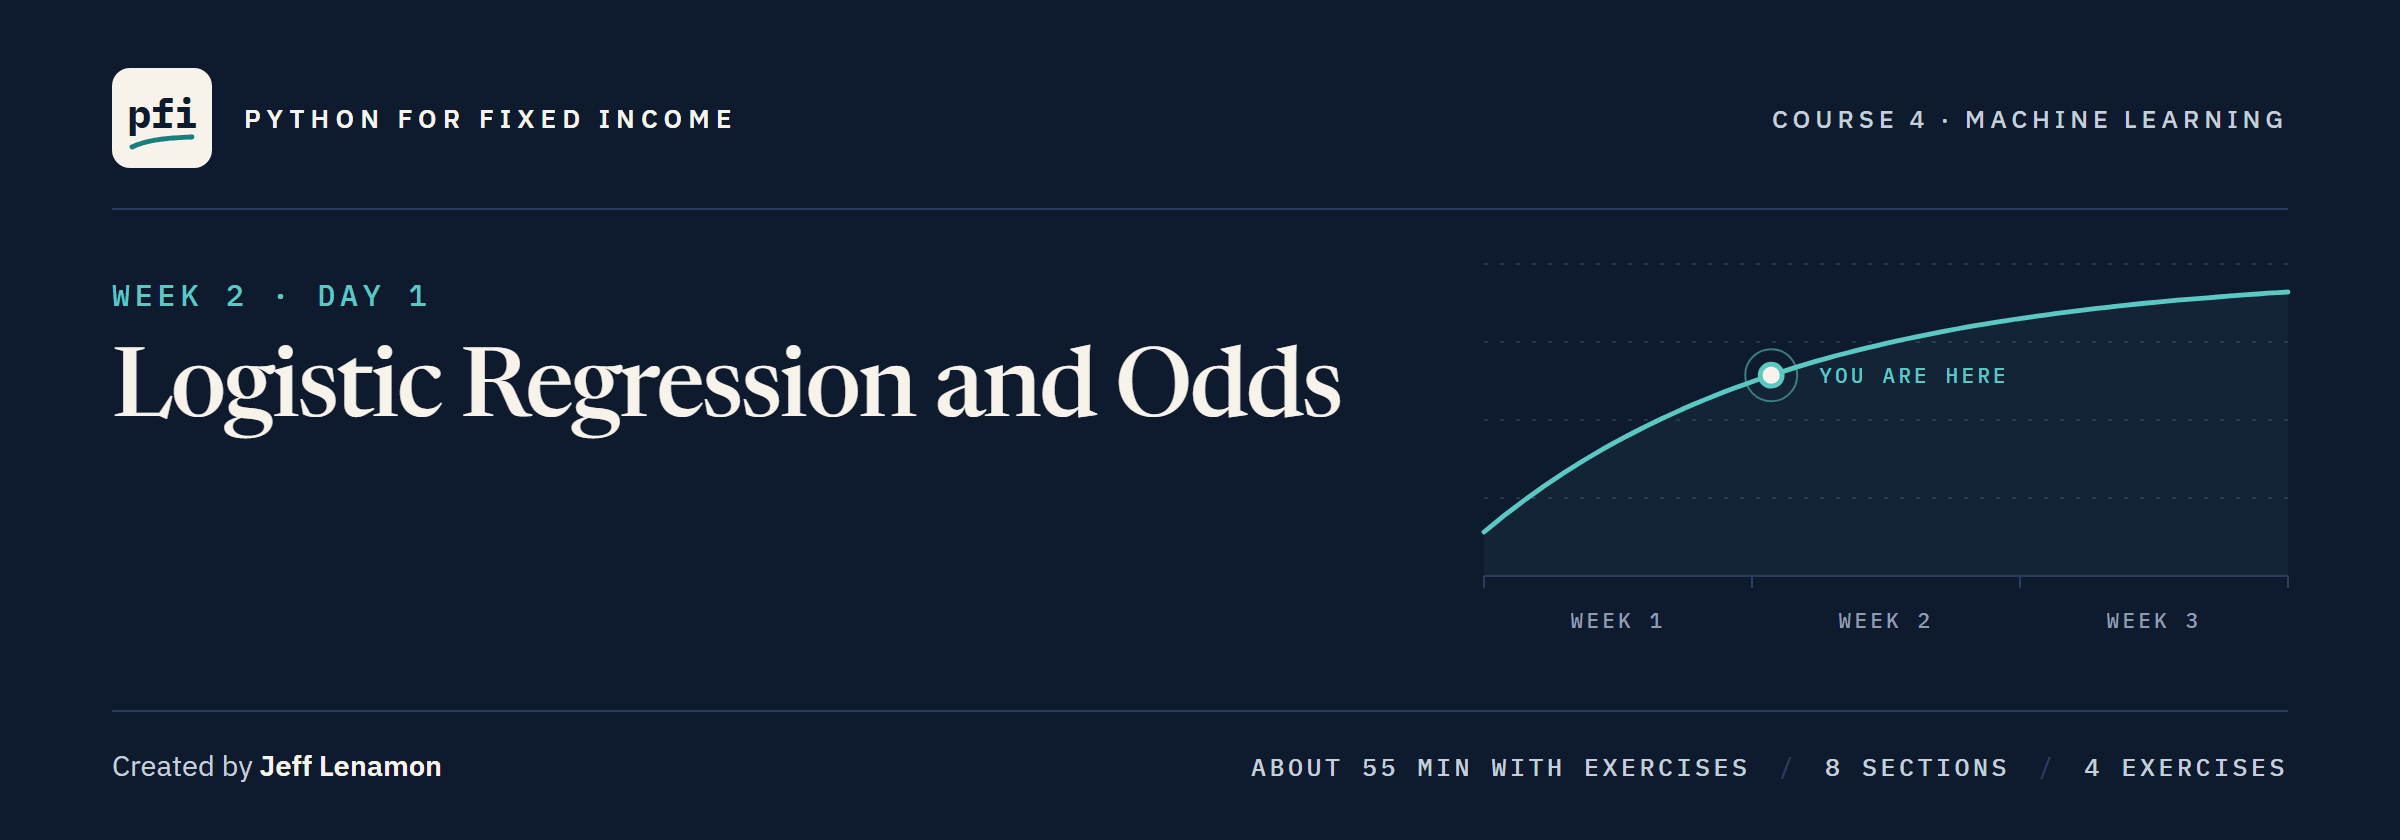

# Logistic Regression and Odds

Week 2, Day 1. Fit a logistic regression of default, read each slope as an odds ratio, and score its probabilities on unseen accounts.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day1/06_logistic_regression_and_odds.ipynb)

# Problem Statement

## Business Context

Week 1 asked how wide a spread is; credit work also asks whether a borrower pays.
A public file of 30,000 credit card accounts records whether each one defaulted the following month.
The accounts are real, in Taiwan in 2005, so nothing here carries over to another market or year.
`SEX`, `EDUCATION`, `MARRIAGE` and `AGE` are never features: a model using them would sort people by them, and leaving them out does not make a model neutral, because other columns can carry the same information.
The output is a model probability of default in this file, never a credit decision about anyone.

## Objectives

Fit a logistic regression by eye and then by computer, read its coefficients as odds ratios with their units, and score its probabilities on accounts it never saw.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `ID`: a row label, never a feature
2. `LIMIT_BAL`: the credit limit, NT dollars
3. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April (-1 paid duly, 1 to 9 months late, -2 and 0 undocumented)
4. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
5. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
6. `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: about the person, never features
7. `default payment next month`: 1 if the account defaulted the following month, 0 if not, **the target**

## Your Route Through Day 1

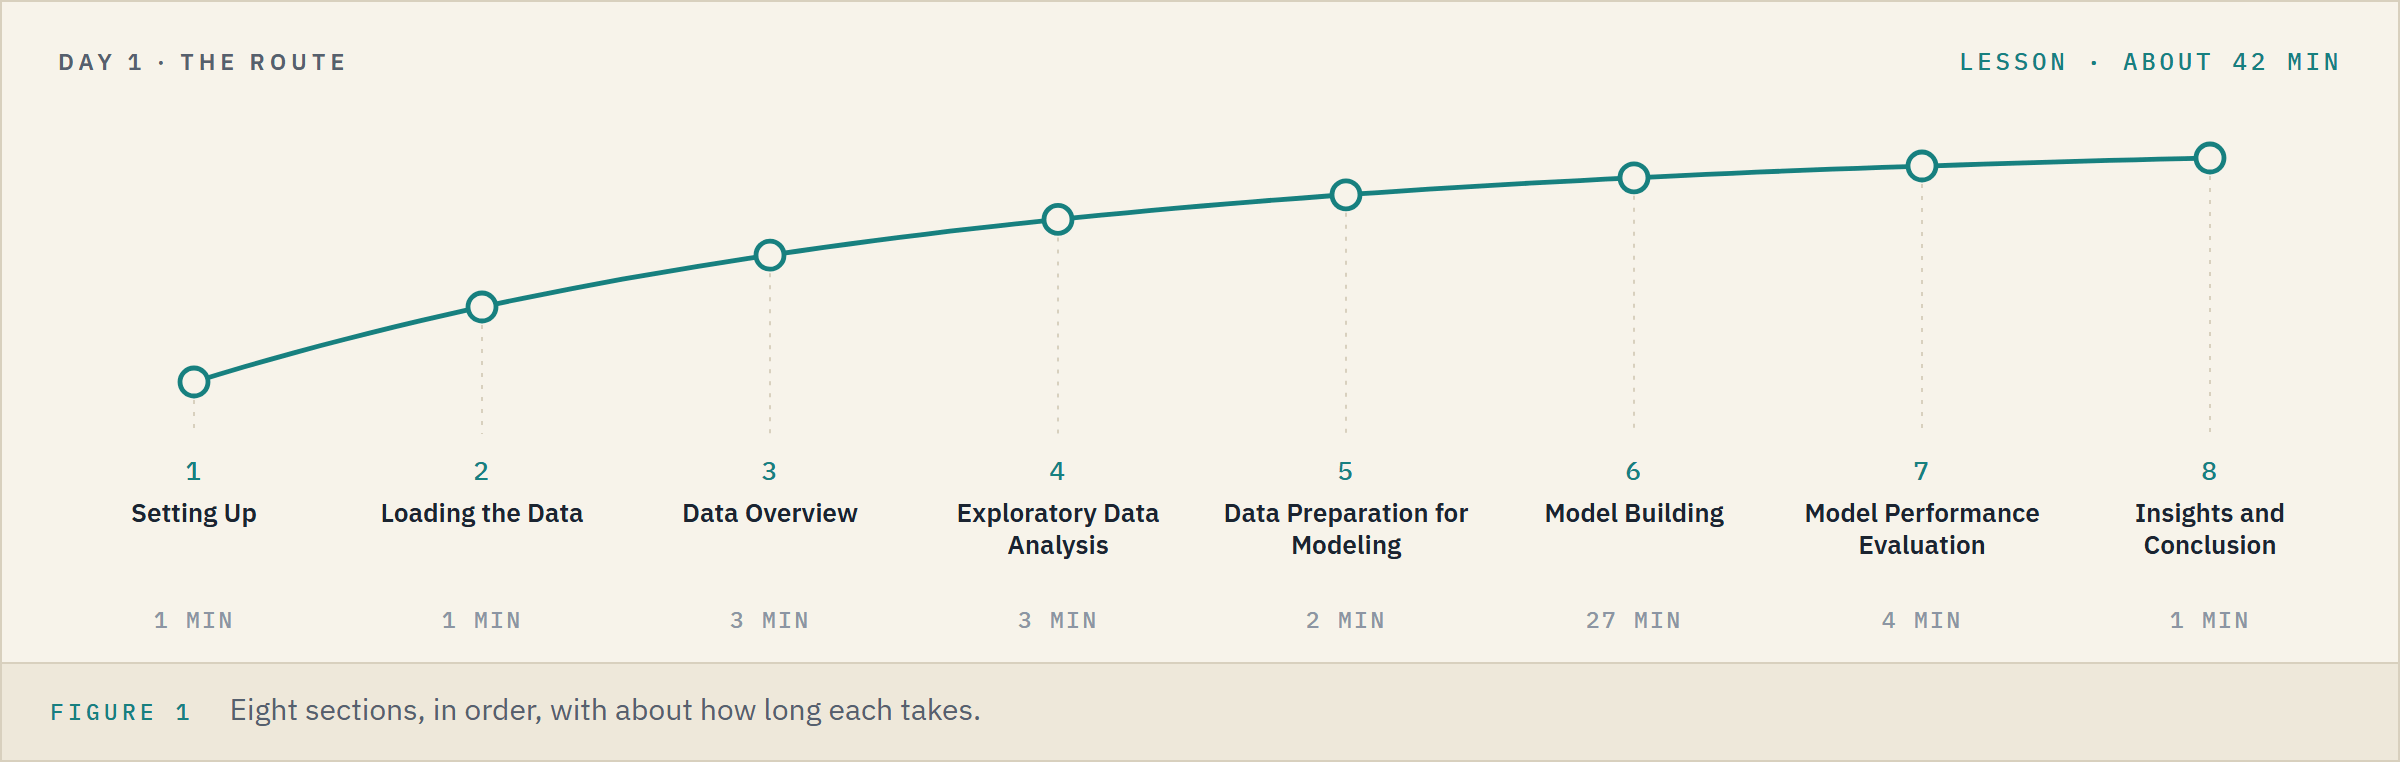

**Time.** About 42 minutes for the lesson, then about 12 for the four exercises.

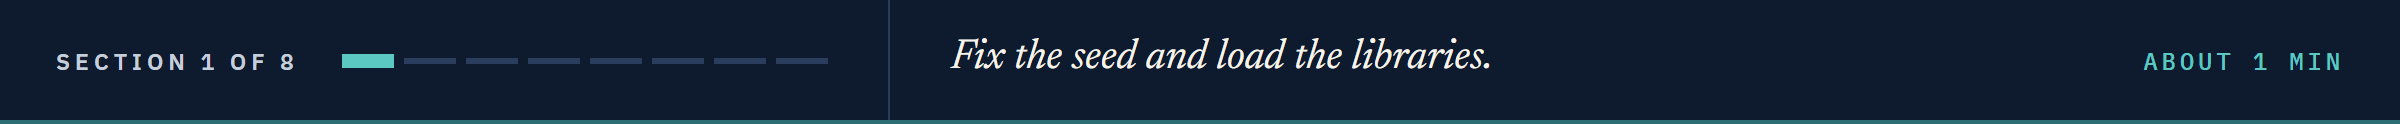

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and the sliders
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts and fit the models
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm

# to score probabilities
from sklearn.metrics import log_loss

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.4f}".format)

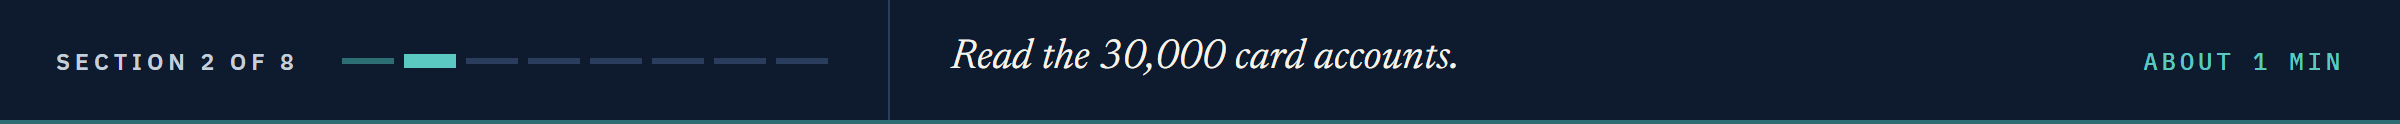

# Loading the Data

## Reading the Card Accounts

In [3]:
# the 30,000 card accounts
card = pd.read_csv(DATA + "credit_card_default.csv")

# the target's name has spaces, so we keep it in a variable
TARGET = "default payment next month"

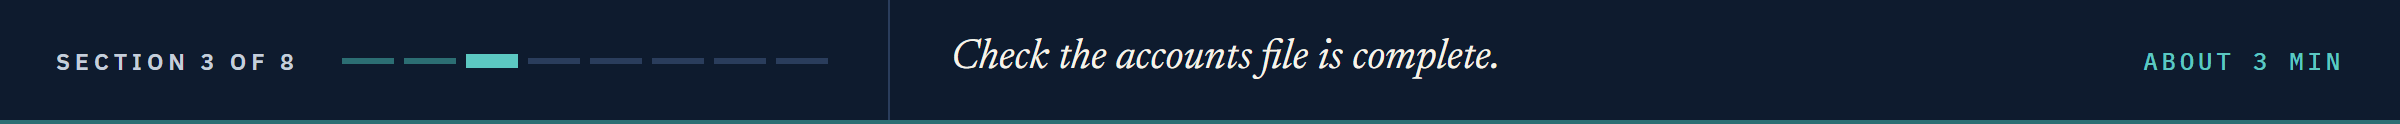

# Data Overview

## Checking the First Five Rows

Q. What does one account look like?

In [4]:
# a few of the 25 columns, and the target
card[["ID", "LIMIT_BAL", "PAY_0", "BILL_AMT1", "PAY_AMT1", TARGET]].head()

,ID,LIMIT_BAL,PAY_0,BILL_AMT1,PAY_AMT1,default payment next month
0,1,20000,2,3913,0,1
1,2,120000,-1,2682,0,1
2,3,90000,0,29239,1518,0
3,4,50000,0,46990,2000,0
4,5,50000,-1,8617,2000,0


One row per account: a limit, six months of status, bills and payments, and the outcome, 0 or 1.

## Checking the Shape of the Data

Q. How many accounts and columns?

In [5]:
card.shape

(30000, 25)

30,000 accounts and 25 columns.

## Checking the Statistical Summary

Q. What range does each kind of column cover?

In [6]:
# one row per column, one column per statistic
card[["LIMIT_BAL", "PAY_0", "BILL_AMT1", "PAY_AMT1", TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,"30,000.0000","167,484.3227","129,747.6616","10,000.0000","50,000.0000","140,000.0000","240,000.0000","1,000,000.0000"
PAY_0,"30,000.0000",-0.0167,1.1238,-2.0000,-1.0000,0.0000,0.0000,8.0000
BILL_AMT1,"30,000.0000","51,223.3309","73,635.8606","-165,580.0000","3,558.7500","22,381.5000","67,091.0000","964,511.0000"
PAY_AMT1,"30,000.0000","5,663.5805","16,563.2804",0.0000,"1,000.0000","2,100.0000","5,006.0000","873,552.0000"
default payment next month,"30,000.0000",0.2212,0.4151,0.0000,0.0000,0.0000,0.0000,1.0000


Limits run from 10,000 to 1,000,000 NT dollars; `PAY_0` runs from -2 to 8.

The target's mean, 0.2212, is the default rate: the mean of a 0/1 column is its share of 1s.

## Checking for Missing and Duplicate Values

Q. Is anything missing, and is any account in the file twice?

In [7]:
# missing values in the whole file, and rows that repeat another row apart from ID
print("Missing values:", card.isnull().sum().sum())
print("Repeated rows: ", card.drop(columns="ID").duplicated().sum())

Missing values: 0
Repeated rows:  35


Nothing is missing.

35 rows repeat another row apart from `ID`: different accounts that look alike, so they stay.

**The file is complete; the only decision is which columns may be features, and the Business Context made it.**

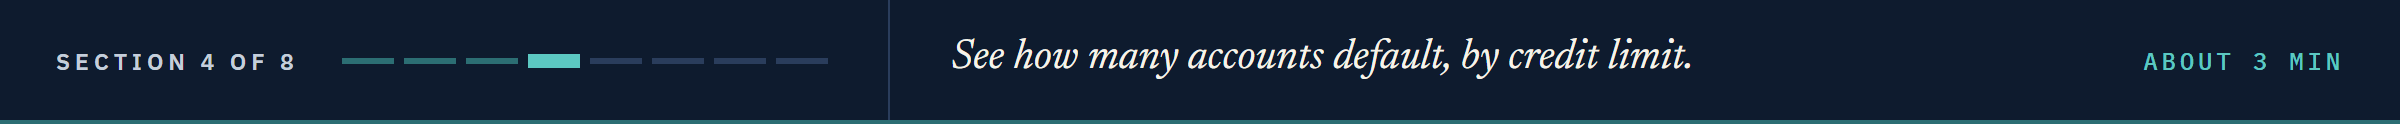

# Exploratory Data Analysis

## Univariate Analysis

### How Many Accounts Defaulted

Q. What share of accounts defaulted the following month?

In [8]:
# the number of defaults, and the default rate in percent
print(card[TARGET].sum(), "of", len(card), "accounts defaulted:", round(card[TARGET].mean() * 100, 2), "percent")

6636 of 30000 accounts defaulted: 22.12 percent


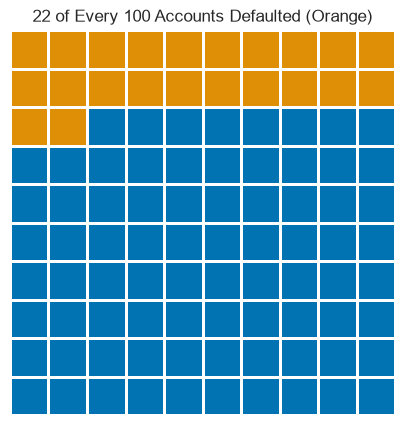

In [9]:
# the default rate as 100 squares, one per percent of accounts (a waffle chart, as Day 3 drew)
squares = (np.arange(100) < round(card[TARGET].mean() * 100)).reshape(10, 10)
plt.figure(figsize=(5, 5))
# "C0" and "C1" are the palette's first two colours, blue and orange; linewidths leaves a gap between squares
sns.heatmap(squares, cmap=["C0", "C1"], cbar=False, linewidths=2, square=True, xticklabels=False, yticklabels=False)
plt.title("22 of Every 100 Accounts Defaulted (Orange)")
plt.show()

About one account in five defaulted, so a model that always answers "no default" is right most of the time: Day 7 opens that trap.

## Bivariate Analysis

### Credit Limit by Outcome

Q. Do accounts that defaulted have lower limits?

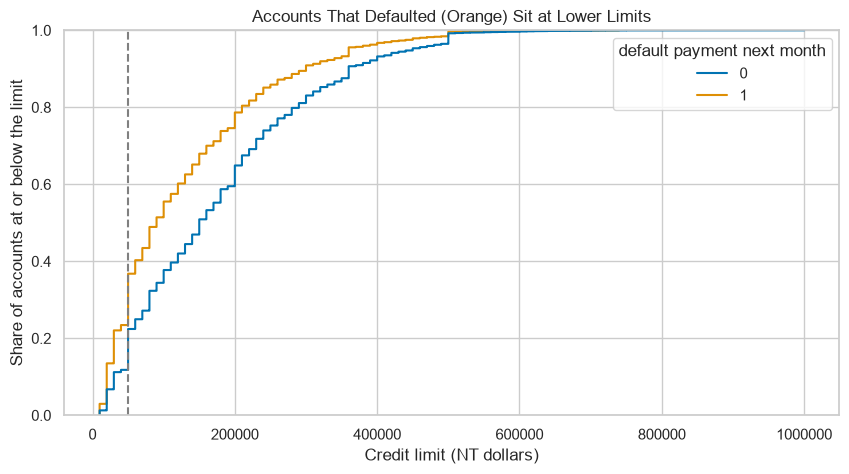

In [10]:
# for each limit, the share of accounts at or below it, one line per outcome (Day 2's ECDF)
sns.ecdfplot(data=card, x="LIMIT_BAL", hue=TARGET)
plt.axvline(50000, color="gray", linestyle="--")
plt.xlabel("Credit limit (NT dollars)")
plt.ylabel("Share of accounts at or below the limit")
plt.ticklabel_format(style="plain", axis="x")  # whole numbers on the axis, not 1e6
plt.title("Accounts That Defaulted (Orange) Sit at Lower Limits")
plt.show()

In [11]:
# the median limit, and the share at or below 50,000 NT dollars, for each outcome
# (.groupby also takes another column of the same rows, here the target)
print(card.groupby(TARGET)["LIMIT_BAL"].median())
print((card["LIMIT_BAL"] <= 50000).groupby(card[TARGET]).mean().round(4))

default payment next month
0   150,000.0000
1    90,000.0000
Name: LIMIT_BAL, dtype: float64
default payment next month
0   0.2241
1   0.3677
Name: LIMIT_BAL, dtype: float64


The orange line runs above the blue at every limit: the accounts that defaulted sit at lower limits.

Median limits: 90,000 NT dollars for accounts that defaulted, 150,000 for the rest.

37 percent of defaulted accounts have a limit of 50,000 or less, against 22 percent of the rest.

**Lower limits go with more defaults. Next, the week's split; repayment status waits for the training accounts.**

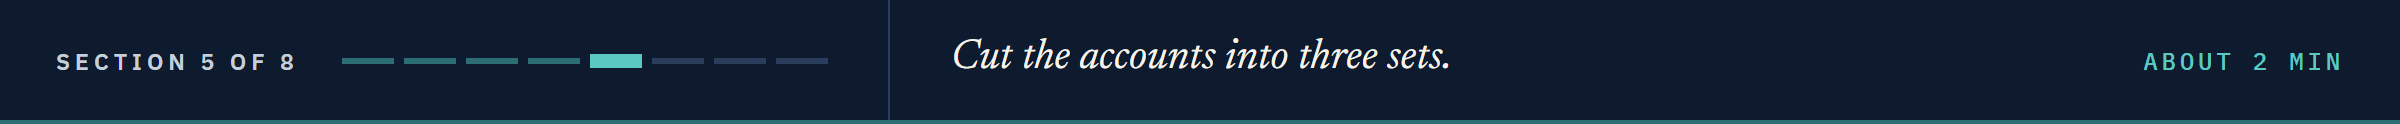

# Data Preparation for Modeling

## Choosing the Features and the Target

In [12]:
# the four columns about the person are never features, and ID is only a row label
PERSON_COLUMNS = ["SEX", "EDUCATION", "MARRIAGE", "AGE"]
FEATURES = [column for column in card.columns if column not in ["ID", TARGET] + PERSON_COLUMNS]
X = card[FEATURES]
y = card[TARGET]
print(len(FEATURES), "features:", FEATURES)

19 features: ['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']


19 features: the limit, six months of status, six bills and six payments.

## Splitting Into Training, Validation and Test Accounts

Week 2 cuts the accounts three ways.

Validation accounts are a second held-back set for checking and comparing models, so the test accounts stay unseen until Day 10.

`stratify=y` keeps the default rate the same in every part.

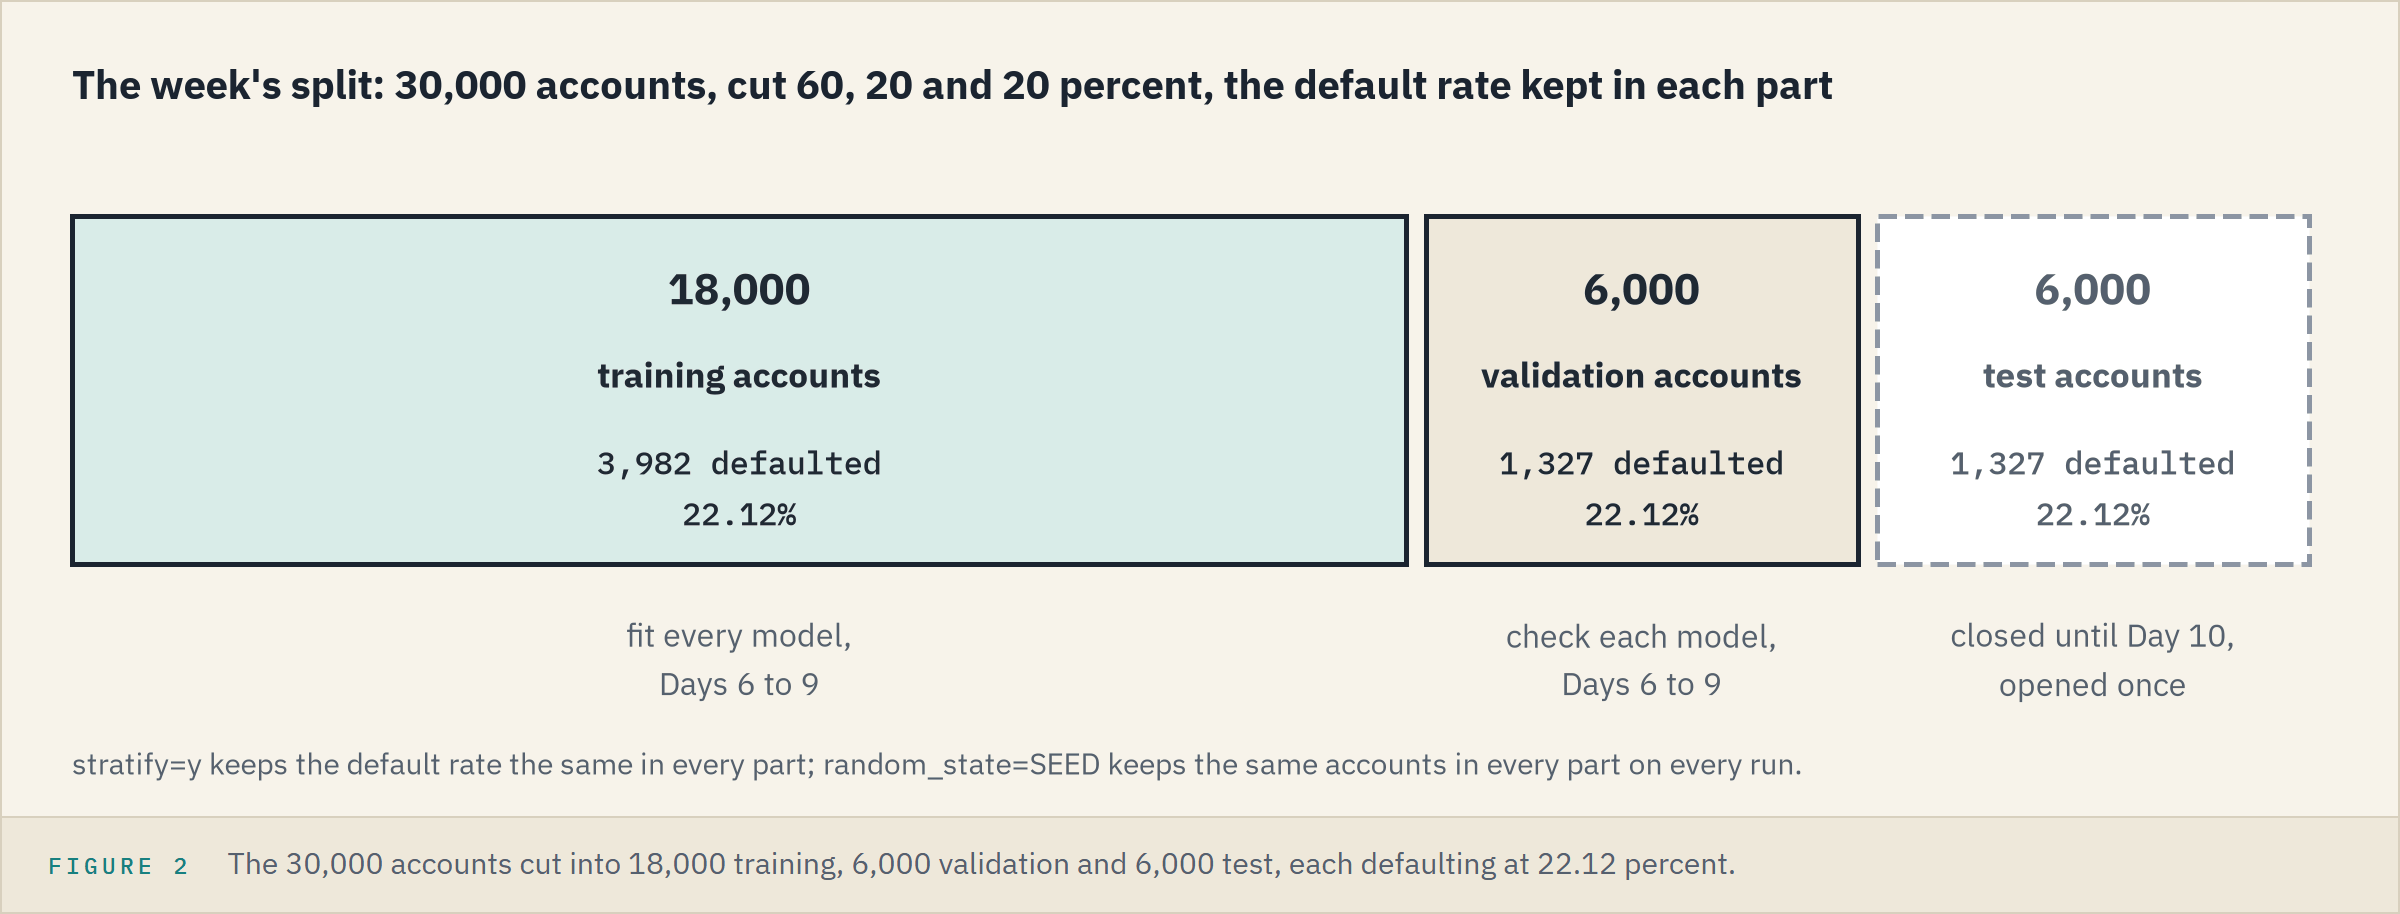

In [13]:
# first a fifth of the accounts become test accounts, put away until Day 10
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

# then a quarter of the rest become validation accounts: 60, 20 and 20 percent in all
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default rate in each:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

Training: 18000  Validation: 6000  Test: 6000
Default rate in each: 0.2212 0.2212 0.2212


**Days 6 to 9 fit on training accounts and check on validation accounts; the test accounts stay closed until Day 10.**

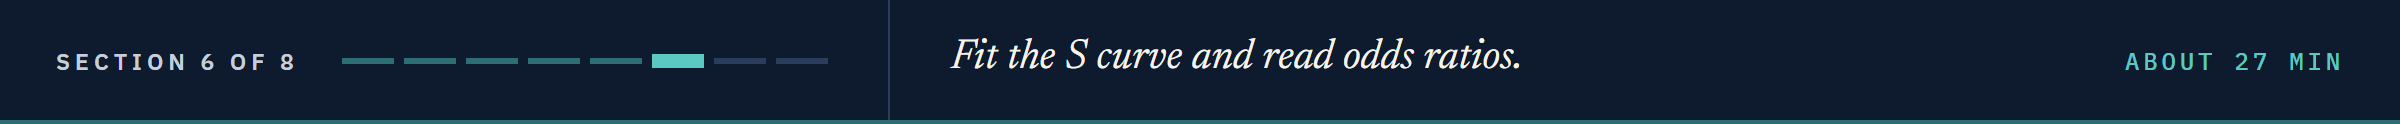

# Model Building

## A Straight Line on a 0/1 Outcome

Q. What does week 1's straight line do with an outcome that is only 0 or 1?

`PAY_0`, the September status, is the first feature to try.

In [14]:
# week 1's model: a straight line of the 0/1 outcome on PAY_0, fitted on the training accounts
line = LinearRegression()
line.fit(X_train[["PAY_0"]], y_train)
print("default = (", round(line.coef_[0], 4), ") * PAY_0 + (", round(line.intercept_, 4), ")")

default = ( 0.1245 ) * PAY_0 + ( 0.2226 )


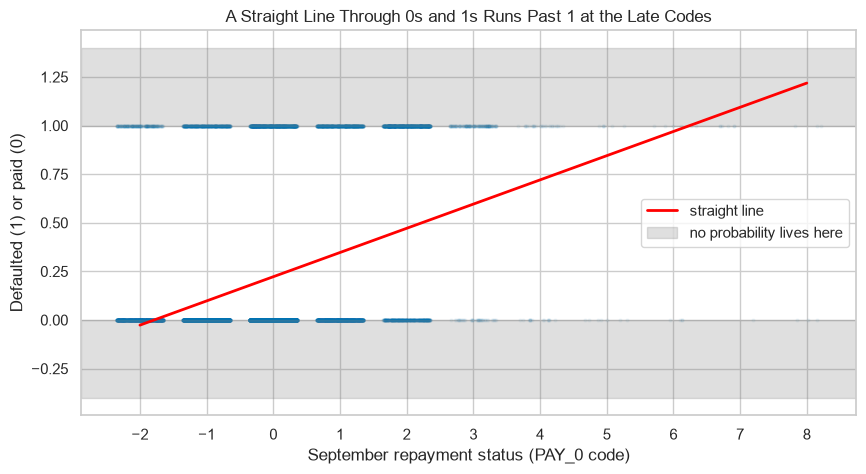

In [15]:
# each account as a dot at 0 or 1, shifted a little sideways at random so the dots do not sit on top of each other (jitter):
# rng.uniform draws numbers spread evenly between its two ends
rng = np.random.default_rng(SEED)
codes = np.arange(-2, 9)
plt.scatter(X_train["PAY_0"] + rng.uniform(-0.35, 0.35, len(X_train)), y_train, s=4, alpha=0.05)
plt.plot(codes, line.predict(pd.DataFrame({"PAY_0": codes})), color="red", linewidth=2, label="straight line")
plt.axhspan(1, 1.4, color="gray", alpha=0.25, label="no probability lives here")
plt.axhspan(-0.4, 0, color="gray", alpha=0.25)
plt.xticks(codes)
plt.xlabel("September repayment status (PAY_0 code)")
plt.ylabel("Defaulted (1) or paid (0)")
plt.title("A Straight Line Through 0s and 1s Runs Past 1 at the Late Codes")
plt.legend(loc="center right")
plt.show()

The top row of dots defaulted, the bottom row paid.

The line climbs 0.1245 per code step and leaves the 0 to 1 range at both ends.

Q. How many validation accounts get a value no probability can take?

In [16]:
# the line's output on the validation accounts
line_valid = line.predict(X_valid[["PAY_0"]])
print("Lowest:", round(line_valid.min(), 4), " Highest:", round(line_valid.max(), 4))
print("Below 0:", (line_valid < 0).sum(), " Above 1:", (line_valid > 1).sum())

Lowest: -0.0264  Highest: 1.2185
Below 0: 578  Above 1: 12


578 validation accounts get a value below 0, all at code -2, and 12 a value above 1.

**A probability lives between 0 and 1, so a straight line needs a scale that can take any value. Log odds are that scale.**

## Probability, Odds and Log Odds

The odds are p / (1 - p): defaults for every account that paid.

The log odds are the natural log of the odds, `np.log` in Python.

<table align="left">
<tr><th align="left">Scale</th><th align="left">At a default rate of 0.20</th><th align="left">Read as</th></tr>
<tr><td align="left">Probability</td><td align="left">0.20</td><td align="left">20 defaults in 100 accounts</td></tr>
<tr><td align="left">Odds</td><td align="left">0.25</td><td align="left">one default for every four accounts that paid</td></tr>
<tr><td align="left">Log odds</td><td align="left">-1.3863</td><td align="left">ln(0.25)</td></tr>
</table>
<br clear="left">

**Predict 1**

Write down the log odds of a default rate of 0.80.

In [17]:
# a default rate of 0.80, as odds and as log odds
p = 0.80
print("Odds:", round(p / (1 - p), 4), " Log odds:", round(np.log(p / (1 - p)), 4))

Odds: 4.0  Log odds: 1.3863


0.80 gives log odds of +1.3863: 0.20's number with the sign flipped, because 0.20 and 0.80 sit equally far from 0.5.

A probability of 0.5 is odds of 1 and log odds of 0.

### Five Rates on Three Scales

Q. How do the three scales stretch the same five rates?

In [18]:
# five default rates on all three scales
rates = np.array([0.1, 0.2, 0.5, 0.8, 0.9])
scales = pd.DataFrame({"probability": rates, "odds": rates / (1 - rates)})
scales["log odds"] = np.log(scales["odds"])
scales

,probability,odds,log odds
0,0.1000,0.1111,-2.1972
1,0.2000,0.2500,-1.3863
2,0.5000,1.0000,0.0000
3,0.8000,4.0000,1.3863
4,0.9000,9.0000,2.1972


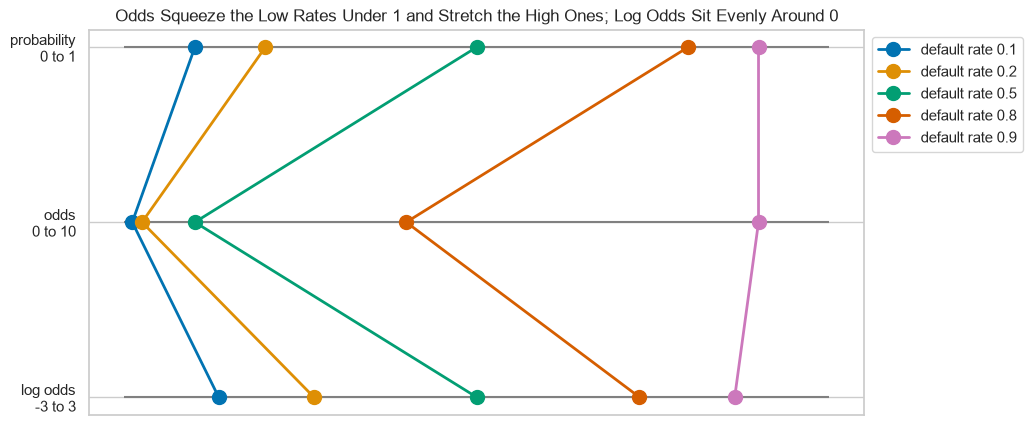

In [19]:
# three number lines, each stretched to run 0 to 10 across the chart, and one line joining each rate across them
plt.hlines([2, 1, 0], 0, 10, color="gray")
for rate, rate_odds, rate_log_odds in scales.to_numpy():
    xs = [rate * 10, rate_odds, (rate_log_odds + 3) * 10 / 6]
    plt.plot(xs, [2, 1, 0], marker="o", markersize=10, linewidth=2, label="default rate " + str(rate))
plt.yticks([2, 1, 0], ["probability\n0 to 1", "odds\n0 to 10", "log odds\n-3 to 3"])
plt.xticks([])
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))  # the key outside the chart, on the right
plt.title("Odds Squeeze the Low Rates Under 1 and Stretch the High Ones; Log Odds Sit Evenly Around 0")
plt.show()

On the odds line, 0.1, 0.2 and 0.5 squeeze between 0 and 1 while 0.8 and 0.9 stretch out to 4 and 9.

On the log odds line they sit evenly around 0, in mirror pairs, and log odds run from minus to plus infinity: a straight line can live there.

## The Default Rate by Repayment Status

Q. How do the rate, odds and log odds move along the `PAY_0` codes, on the training accounts?

In [20]:
# the training accounts by September status: how many, how many defaulted, and the three scales
by_code = y_train.groupby(X_train["PAY_0"]).agg(accounts="size", defaults="sum")
by_code["rate"] = by_code["defaults"] / by_code["accounts"]
by_code["odds"] = by_code["rate"] / (1 - by_code["rate"])
by_code["log_odds"] = np.log(by_code["odds"])
by_code

,accounts,defaults,rate,odds,log_odds
PAY_0,,,,,
-2,1620,202,0.1247,0.1425,-1.9487
-1,3419,565,0.1653,0.1980,-1.6197
0,8807,1113,0.1264,0.1447,-1.9334
1,2269,780,0.3438,0.5238,-0.6466
2,1618,1125,0.6953,2.2819,0.8250
3,188,148,0.7872,3.7000,1.3083
4,43,28,0.6512,1.8667,0.6242
5,13,6,0.4615,0.8571,-0.1542
6,10,6,0.6000,1.5000,0.4055


At code 2, two months late, 1,125 of 1,618 accounts defaulted: a rate of 0.6953, odds of 2.28.

Codes 4 to 8 hold only 43, 13, 10, 7 and 6 accounts, so their rates jump around.

Codes -2 (0.1247) and 0 (0.1264) sit below -1 (0.1653): using the codes as evenly spaced numbers is a modelling choice, and we watch where it costs.

## The S Curve

The logistic curve, `1 / (1 + np.exp(-z))`, turns log odds z back into a probability: an S curve.

In [21]:
# the logistic curve turns any number z into a probability between 0 and 1
def logistic(z):
    return 1 / (1 + np.exp(-z))

print(logistic(np.array([-4, -2, 0, 2, 4])).round(4))

[0.018  0.1192 0.5    0.8808 0.982 ]


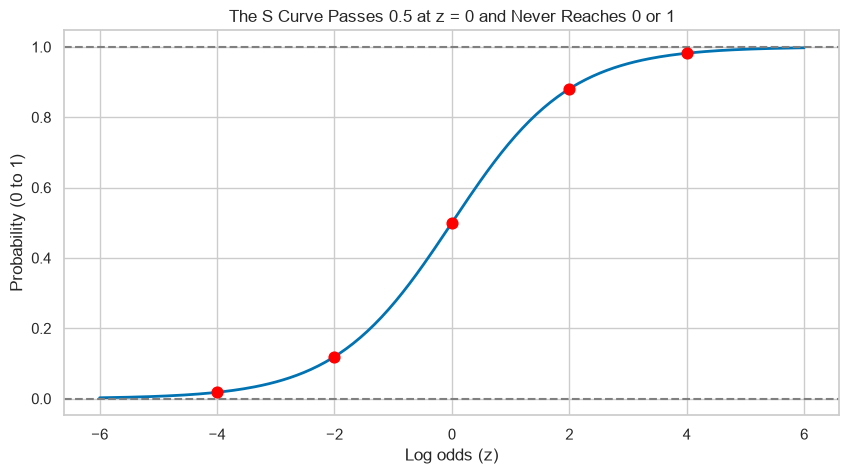

In [22]:
# the curve from z = -6 to 6, with the five values marked
z_values = np.linspace(-6, 6, 201)
marks = np.array([-4, -2, 0, 2, 4])
plt.plot(z_values, logistic(z_values), linewidth=2)
plt.scatter(marks, logistic(marks), color="red", s=60, zorder=3)
plt.axhline(0, color="gray", linestyle="--")
plt.axhline(1, color="gray", linestyle="--")
plt.xlabel("Log odds (z)")
plt.ylabel("Probability (0 to 1)")
plt.title("The S Curve Passes 0.5 at z = 0 and Never Reaches 0 or 1")
plt.show()

z = 0 gives 0.5, and z = 2 and -2 give a mirror pair, 0.8808 and 0.1192.

The curve never reaches 0 or 1.

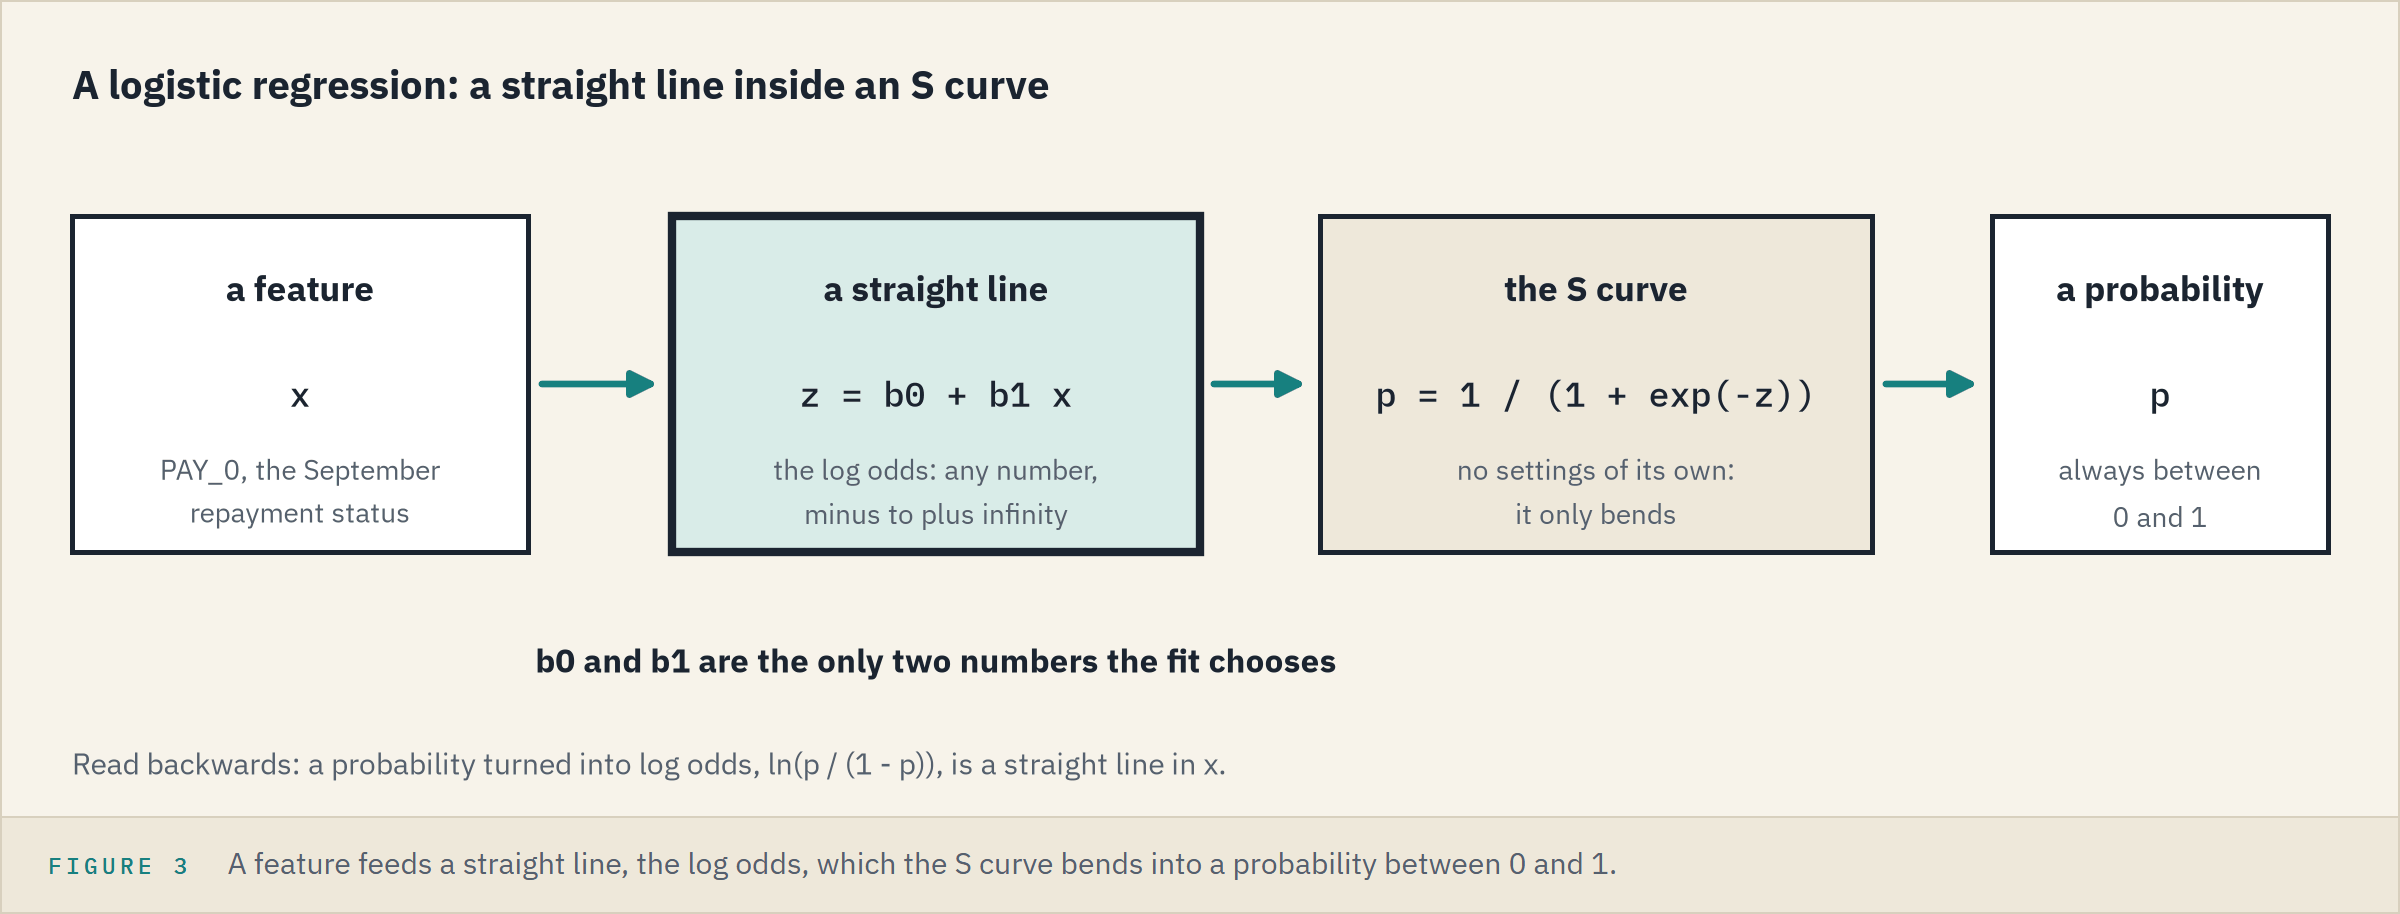

The curve has no settings: a logistic regression fits the straight line inside it, two numbers, as Day 1's line did.

## Your Turn: Fit the Curve by Eye

A curve's score is its log-likelihood: for each training account, the log of the probability the curve gave to what happened, added over all 18,000.

Every score is below 0; closer to 0 is better.

In [23]:
# the log-likelihood of a curve with this intercept and slope, on the training accounts
def log_likelihood(intercept, slope):
    p = logistic(intercept + slope * X_train["PAY_0"])
    return np.sum(y_train * np.log(p) + (1 - y_train) * np.log(1 - p))

Move the sliders until the red curve runs through the dots, one per code, sized by accounts.

Find the highest log-likelihood you can, and write down your intercept and slope.

In [24]:
# your turn: move the two sliders until the curve runs through the dots
def draw_curve(intercept=-1.26, slope=0.0):
    curve_codes = np.linspace(-2, 8, 101)
    plt.scatter(by_code.index, by_code["rate"], s=by_code["accounts"] / 10, alpha=0.5)
    plt.plot(curve_codes, logistic(intercept + slope * curve_codes), color="red")
    plt.ylim(-0.05, 1.05)
    plt.xlabel("September repayment status (PAY_0 code)")
    plt.ylabel("Default rate (0 to 1)")
    plt.title("Your Curve Through the Training Default Rates")
    plt.show()
    print("Log-likelihood:", round(log_likelihood(intercept, slope), 1))

interact(draw_curve, intercept=(-3.0, 1.0, 0.02), slope=(0.0, 1.5, 0.02));

interactive(children=(FloatSlider(value=-1.26, description='intercept', max=1.0, min=-3.0, step=0.02), FloatSl…

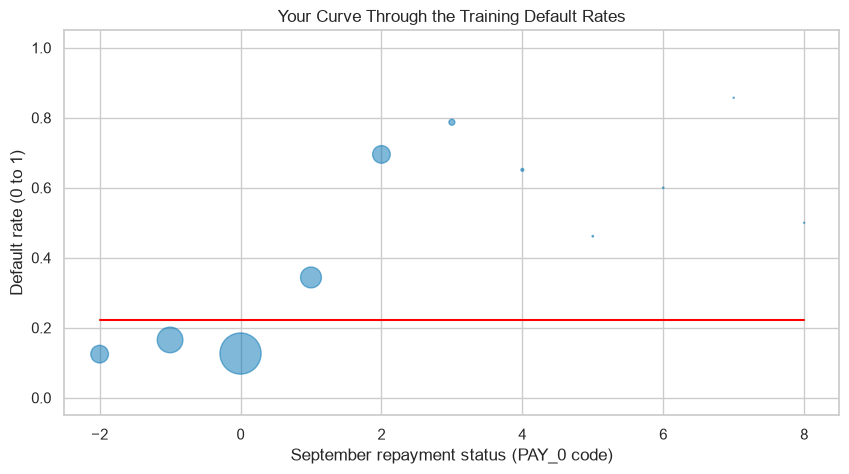

Log-likelihood: -9512.1


In [25]:
# the sliders' starting position, drawn as a still picture (sliders do not run on GitHub)
draw_curve(intercept=-1.26, slope=0.0)

The sliders start flat at the training default rate, about 0.22 for every account: log-likelihood -9,512.1, the score every slope has to beat.

## Logistic Regression With `statsmodels`

Now the computer turns the same two knobs.

`sm.Logit` works like Day 3's `sm.OLS`, with `sm.add_constant` for the intercept; `.fit(disp=0)` fits without printing the solver's progress.

In [26]:
# fit the logistic regression of default on PAY_0, on the training accounts
logit_pay = sm.Logit(y_train, sm.add_constant(X_train[["PAY_0"]])).fit(disp=0)
print("Log-likelihood:", round(logit_pay.llf, 1))

Log-likelihood: -8495.9


In [27]:
# the coefficient table: each coefficient, its standard error and its p-value (Day 3's columns)
pd.DataFrame({"coef": logit_pay.params, "std err": logit_pay.bse, "p-value": logit_pay.pvalues})

,coef,std err,p-value
const,-1.4185,0.0203,0.0000
PAY_0,0.7702,0.0187,0.0000


Intercept -1.4185 and slope 0.7702, with p-values too small to show.

Its log-likelihood, -8,495.9, is the highest any intercept and slope can reach here: no slider setting beats it.

## One Model, Two Scales

Q. What does the fitted model look like on the log odds scale, and on the probability scale?

In [28]:
# the fitted log odds across the codes, and week 1's straight line on the same codes
curve_codes = np.linspace(-2, 8, 101)
fitted_z = logit_pay.params["const"] + logit_pay.params["PAY_0"] * curve_codes
straight = line.predict(pd.DataFrame({"PAY_0": curve_codes}))

# the code where the log odds are 0, so the model probability is 0.5
crossing = -logit_pay.params["const"] / logit_pay.params["PAY_0"]
print("The model crosses 0.5 at code", round(crossing, 2))

The model crosses 0.5 at code 1.84


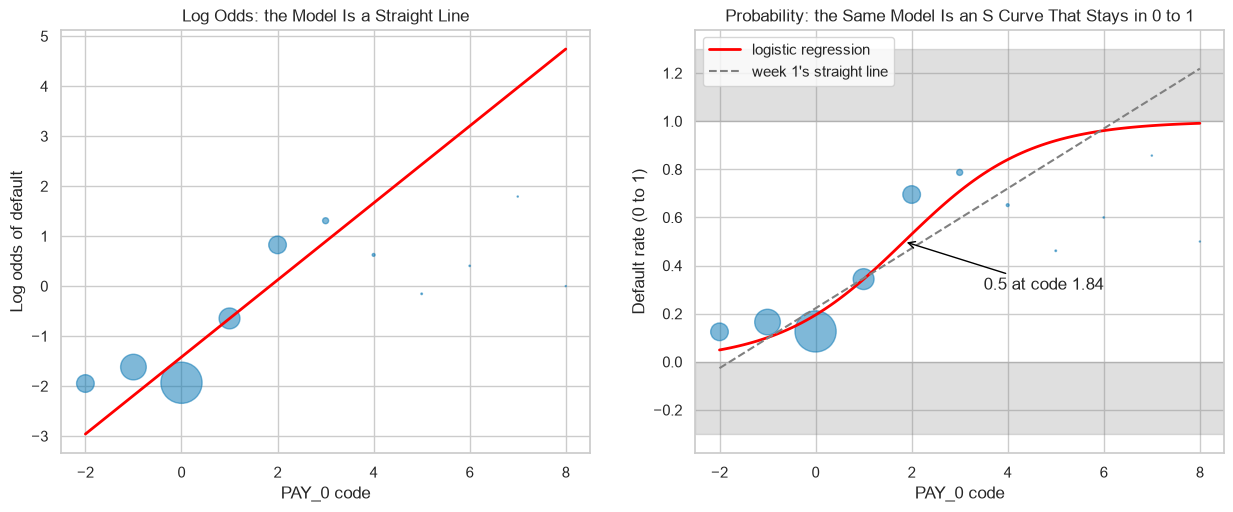

In [29]:
# left: log odds, where the model is a straight line; right: probability, where it is an S curve (.set names several labels at once)
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5.5))
left.scatter(by_code.index, by_code["log_odds"], s=by_code["accounts"] / 10, alpha=0.5)
left.plot(curve_codes, fitted_z, color="red", linewidth=2)
left.set(xlabel="PAY_0 code", ylabel="Log odds of default", title="Log Odds: the Model Is a Straight Line")
right.scatter(by_code.index, by_code["rate"], s=by_code["accounts"] / 10, alpha=0.5)
right.plot(curve_codes, logistic(fitted_z), color="red", linewidth=2, label="logistic regression")
right.plot(curve_codes, straight, color="gray", linestyle="--", label="week 1's straight line")
right.axhspan(1, 1.3, color="gray", alpha=0.25)
right.axhspan(-0.3, 0, color="gray", alpha=0.25)
right.annotate("0.5 at code " + str(round(crossing, 2)), xy=(crossing, 0.5), xytext=(3.5, 0.3), arrowprops={"arrowstyle": "->", "color": "black"})
right.set(xlabel="PAY_0 code", ylabel="Default rate (0 to 1)", title="Probability: the Same Model Is an S Curve That Stays in 0 to 1")
right.legend(loc="upper left")
plt.show()

A straight line in log odds is an S curve in probability, and it never leaves 0 to 1.

The curve crosses 0.5 at code 1.84, where the log odds are 0.

Neither model follows codes -2 to 0, the modelling choice the table showed.

The big dots pull hardest: the fit weighs every account, not every code.

### Interpretation of the Coefficients

In [30]:
# the slope as an odds ratio: e to the power of the coefficient
print("Odds ratio per code step:", round(np.exp(logit_pay.params["PAY_0"]), 4))

# the intercept as a probability: the model at code 0
print("Model probability at code 0:", round(logistic(logit_pay.params["const"]), 4))

Odds ratio per code step: 2.1602
Model probability at code 0: 0.1949


An odds ratio, e to the power of a coefficient, says how many times as high the odds are after one step of the feature.

Each code step goes with odds of default 2.16 times as high, in this file: an association, not a cause.

The intercept is the log odds at code 0, a model probability of 0.1949.

## Scoring the Curve on Validation Accounts

A probability is scored with log loss: the log-likelihood per account, sign flipped, so lower is better.

In [31]:
# the model probability for each account, then the log loss on training and on validation accounts
p_train = logit_pay.predict(sm.add_constant(X_train[["PAY_0"]]))
p_valid = logit_pay.predict(sm.add_constant(X_valid[["PAY_0"]]))
print("Training log loss:  ", round(log_loss(y_train, p_train), 4))
print("Validation log loss:", round(log_loss(y_valid, p_valid), 4))

Training log loss:   0.472
Validation log loss: 0.482


In [32]:
# a flat guess: the training default rate for every validation account (np.full repeats one number)
flat_valid = np.full(len(y_valid), y_train.mean())
print("Flat guess, validation log loss:", round(log_loss(y_valid, flat_valid), 4))

Flat guess, validation log loss: 0.5284


Training 0.4720 is -8,495.9 over 18,000 accounts, sign flipped.

On validation accounts the curve scores 0.4820, against 0.5284 for the flat guess.

**The curve beats a flat guess on accounts it never saw. Next, how the computer found its two numbers.**

## How the Fit Chooses: Maximum Likelihood

Least squares had a formula; the logistic fit has none.

A solver climbs the log-likelihood step by step to its highest point: maximum likelihood.

A grid of intercepts and slopes shows the hill.

In [33]:
# the log-likelihood at every pair on a 41 by 41 grid of intercepts and slopes (a few seconds)
intercepts = np.linspace(-2.5, -0.5, 41)
slopes = np.linspace(-0.2, 1.4, 41)
heights = [[log_likelihood(a, b) for a in intercepts] for b in slopes]

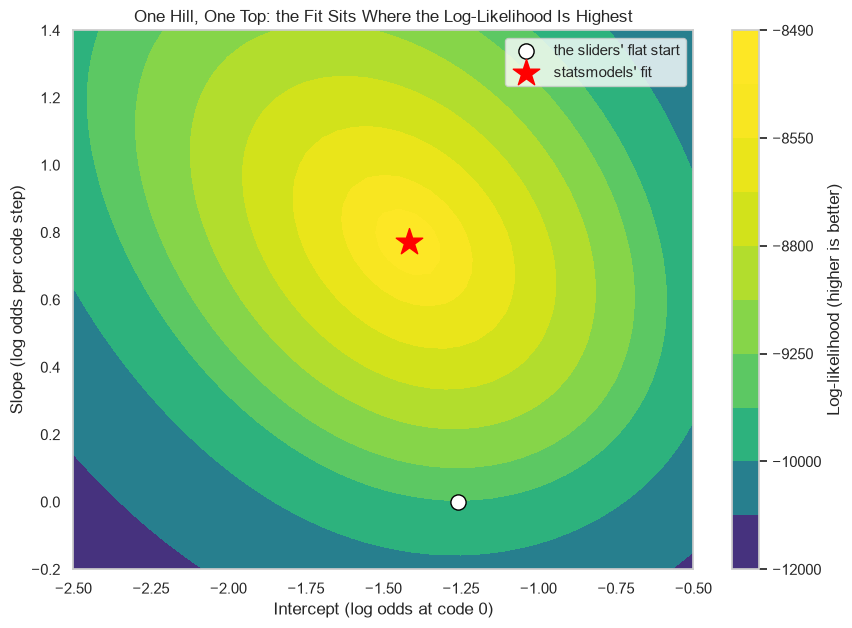

In [34]:
# the hill as a filled contour map (plt.contourf fills Day 3's contour lines), the flat start and the fit marked
plt.figure(figsize=(10, 7))
plt.contourf(intercepts, slopes, heights, levels=[-12000, -11000, -10000, -9500, -9250, -9000, -8800, -8650, -8550, -8510, -8490], cmap="viridis")
plt.colorbar(label="Log-likelihood (higher is better)")
plt.scatter(-1.26, 0, color="white", edgecolor="black", s=120, label="the sliders' flat start", zorder=3)
plt.scatter(logit_pay.params["const"], logit_pay.params["PAY_0"], color="red", marker="*", s=400, label="statsmodels' fit", zorder=3)
plt.xlabel("Intercept (log odds at code 0)")
plt.ylabel("Slope (log odds per code step)")
plt.title("One Hill, One Top: the Fit Sits Where the Log-Likelihood Is Highest")
plt.legend(loc="upper right")
plt.show()

One hill, one top, wherever the solver starts: intercept -1.42 and slope 0.77, statsmodels' numbers.

**One feature gives one hill. Adding the credit limit gives each feature its own odds ratio.**

## Adding the Credit Limit

A slope's unit is its feature's unit, so the limit goes in as units of 10,000 NT dollars, added with `.assign` (Course 1).

In [35]:
# PAY_0 and the limit in units of 10,000 NT dollars, for training and for validation accounts
X2_train = X_train[["PAY_0"]].assign(LIMIT_10K=X_train["LIMIT_BAL"] / 10000)
X2_valid = X_valid[["PAY_0"]].assign(LIMIT_10K=X_valid["LIMIT_BAL"] / 10000)

# the two-feature fit, on the training accounts
logit_two = sm.Logit(y_train, sm.add_constant(X2_train)).fit(disp=0)

In [36]:
# each coefficient as an odds ratio, with its 95 percent interval and the percent change in odds
ratios = np.exp(logit_two.conf_int())
ratios.columns = ["lower", "upper"]
ratios["odds ratio"] = np.exp(logit_two.params)
ratios["change in odds (%)"] = (ratios["odds ratio"] - 1) * 100
print("Correlation of PAY_0 with the limit:", round(X_train["PAY_0"].corr(X_train["LIMIT_BAL"]), 2))
ratios

Correlation of PAY_0 with the limit: -0.27


,lower,upper,odds ratio,change in odds (%)
const,0.3117,0.3537,0.3320,-66.7995
PAY_0,1.9812,2.1359,2.0571,105.7090
LIMIT_10K,0.9766,0.9832,0.9799,-2.0122


### Interpretation of the Odds Ratios

Each code step goes with odds 2.06 times as high, holding the limit fixed: 105.7 percent higher.

Each extra 10,000 NT dollars of limit goes with odds 0.98 times as high, holding status fixed: 2.0 percent lower.

Neither interval reaches 1, the odds ratio of no change.

`PAY_0` fell from 2.16 alone to 2.06: higher codes come with lower limits, so the limit now carries part of it.

**Predict 2**

The limit's odds ratio is 0.9799 per 10,000 NT dollars.

Write down its odds ratio per single NT dollar.

In [37]:
# the same coefficient per single NT dollar: divide it by 10,000 before taking e to its power
print("Odds ratio per NT dollar:", np.exp(logit_two.params["LIMIT_10K"] / 10000))

Odds ratio per NT dollar: 0.9999979672654501


0.999998, on 1, though the limit matters exactly as much as before: always state an odds ratio with its unit.

### The Odds Ratios With Their Intervals

Q. How sure is each ratio, and how far does the unit move it?

In [38]:
# three rows: PAY_0 per code step, the limit per 10,000 NT dollars, and the limit per NT dollar
forest = ratios.loc[["PAY_0", "LIMIT_10K"], ["odds ratio", "lower", "upper"]]
forest.loc["per NT dollar"] = forest.loc["LIMIT_10K"] ** (1 / 10000)
forest.index = ["PAY_0, per code step", "limit, per 10,000 NT dollars", "limit, per NT dollar"]

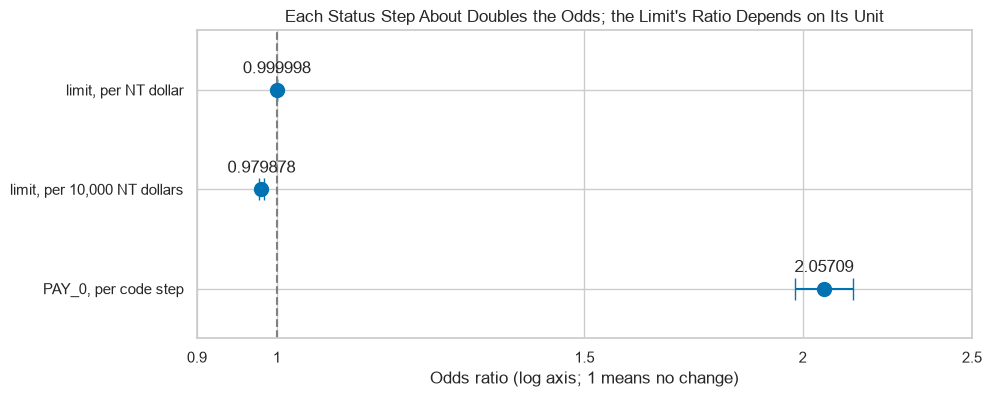

In [39]:
# a forest plot, as Day 3 drew: each ratio with its 95 percent interval (xerr takes the distance to each end), on a log axis
# (markersize sets the dot's size, capsize the width of the whisker's end caps)
plt.figure(figsize=(10, 4))
plt.errorbar(forest["odds ratio"], forest.index, xerr=[forest["odds ratio"] - forest["lower"], forest["upper"] - forest["odds ratio"]], fmt="o", markersize=10, capsize=8)
# each ratio written 12 points above its dot
for name, ratio in forest["odds ratio"].items():
    plt.annotate(str(round(ratio, 6)), (ratio, name), xytext=(0, 12), textcoords="offset points", ha="center")
plt.axvline(1, color="gray", linestyle="--")
plt.xscale("log")
plt.xticks([0.9, 1, 1.5, 2, 2.5], ["0.9", "1", "1.5", "2", "2.5"])
plt.minorticks_off()  # no extra unlabelled ticks between the labelled ones
plt.ylim(-0.5, 2.6)
plt.xlabel("Odds ratio (log axis; 1 means no change)")
plt.title("Each Status Step About Doubles the Odds; the Limit's Ratio Depends on Its Unit")
plt.show()

Status sits far right of 1 with a narrow interval; the limit sits just left of 1, or on it, by its unit.

## One Account, Step by Step

Q. What model probability does one account get, and what happens when its status worsens?

Take a 500,000 NT dollar limit at status code 0.

In [40]:
# one account: the intercept's 1.0, status code 0, and a limit of 500,000 NT dollars (50 units of 10,000)
account = pd.DataFrame({"const": [1.0], "PAY_0": [0], "LIMIT_10K": [50.0]})
p_code0 = logit_two.predict(account)[0]
print("Model probability:", round(p_code0, 4), " Odds:", round(p_code0 / (1 - p_code0), 4))

Model probability: 0.1073  Odds: 0.1202


**Predict 3**

The same account moves to code 2, two months late.

Each code step multiplies the odds by 2.0571.

Write down its model probability.

In [41]:
# the same account at status code 2
account["PAY_0"] = 2
p_code2 = logit_two.predict(account)[0]
print("Model probability:", round(p_code2, 4), " Odds:", round(p_code2 / (1 - p_code2), 4))

Model probability: 0.3371  Odds: 0.5084


The odds go from 0.1202 to 0.5084, 4.23 times (2.0571 squared); the probability from 0.1073 to 0.3371, only about 3 times.

Q. Where does that 0.3371 come from?

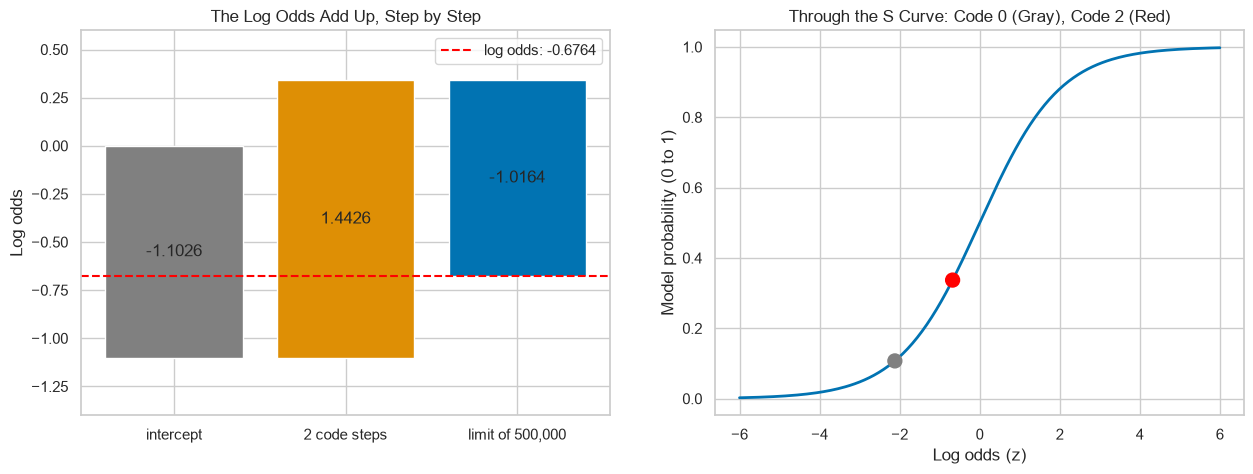

In [42]:
# the account's log odds built step by step (a waterfall, as Day 2 drew), then put through the S curve
steps = pd.Series({"intercept": logit_two.params["const"], "2 code steps": 2 * logit_two.params["PAY_0"],
                   "limit of 500,000": 50 * logit_two.params["LIMIT_10K"]})
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5))
bars = left.bar(steps.index, steps, bottom=steps.cumsum() - steps, color=["gray", "C1", "C0"])
left.bar_label(bars, labels=steps.round(4), label_type="center")
left.axhline(steps.sum(), color="red", linestyle="--", label="log odds: " + str(round(steps.sum(), 4)))
left.set(ylabel="Log odds", ylim=(-1.4, 0.6), title="The Log Odds Add Up, Step by Step")
left.legend()
right.plot(z_values, logistic(z_values), linewidth=2)
right.scatter([steps.sum() - steps["2 code steps"], steps.sum()], [p_code0, p_code2], color=["gray", "red"], s=100, zorder=3)
right.set(xlabel="Log odds (z)", ylabel="Model probability (0 to 1)", title="Through the S Curve: Code 0 (Gray), Code 2 (Red)")
plt.show()

-1.1026, plus 1.4426, minus 1.0164: log odds of -0.6764, which the S curve turns into 0.3371.

**An odds ratio multiplies the odds, never the probability: the line adds in log odds, and the curve bends the sum.**

## The Same Model in `scikit-learn`

`LogisticRegression` adds Day 5's ridge penalty by default, a pull of every coefficient toward zero.

`C` sets its strength (smaller pulls harder) and `C=np.inf` turns it off.

`max_iter=1000` lets the solver take up to 1,000 steps, and `tol=1e-8` runs it to the 8th decimal, for the comparison.

In [43]:
# scikit-learn with the penalty turned off, on the same two columns
sk_two = LogisticRegression(C=np.inf, tol=1e-8, max_iter=1000)
sk_two.fit(X2_train, y_train)

# and with its default penalty, C=1.0
sk_default = LogisticRegression(max_iter=1000)
sk_default.fit(X2_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [44]:
# the three fits side by side, intercept first: scikit-learn keeps them in .intercept_ and .coef_
fits = pd.DataFrame({"statsmodels": logit_two.params,
                     "C=np.inf": [sk_two.intercept_[0]] + list(sk_two.coef_[0]),
                     "C=1.0": [sk_default.intercept_[0]] + list(sk_default.coef_[0])})
print("Largest gap without the penalty:", (fits["statsmodels"] - fits["C=np.inf"]).abs().max())
fits

Largest gap without the penalty: 1.1872645311328256e-08


,statsmodels,C=np.inf,C=1.0
const,-1.1026,-1.1026,-1.1025
PAY_0,0.7213,0.7213,0.7210
LIMIT_10K,-0.0203,-0.0203,-0.0203


Without the penalty the two libraries match to the 8th decimal; with `C=1.0`, no coefficient moves more than 0.0003.

**The libraries agree, so scikit-learn takes all 19 columns.**

## All 19 Columns in a Pipeline

`StandardScaler` rescales each column to mean 0 and standard deviation 1, so every coefficient is per standard deviation.

A `Pipeline` chains scaler and model, so `fit` learns the means and standard deviations from the training accounts only.

In [45]:
# scale every column, then fit the logistic regression with its default penalty, as one pipeline
model = Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scale', ...), ('logit', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['LIMIT_BAL','PAY_0','PAY_2',...,'PAY_AMT4','PAY_AMT5','PAY_AMT6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [46]:
# each column's odds ratio per standard deviation, smallest first (named_steps reaches a step by its name)
odds_19 = np.exp(pd.Series(model.named_steps["logit"].coef_[0], index=FEATURES)).sort_values()
print("Above 1:", (odds_19 > 1).sum(), " Below 1:", (odds_19 < 1).sum())
print("Correlation of BILL_AMT1 with BILL_AMT3:", round(X_train["BILL_AMT1"].corr(X_train["BILL_AMT3"]), 2))

# each column's family, for the colours (.str.startswith tests how a name begins)
family = pd.Series("status", index=odds_19.index)
family[odds_19.index.str.startswith("BILL")] = "bill"
family[odds_19.index.str.startswith("PAY_AMT")] = "payment"
family["LIMIT_BAL"] = "limit"

Above 1: 10  Below 1: 9
Correlation of BILL_AMT1 with BILL_AMT3: 0.9


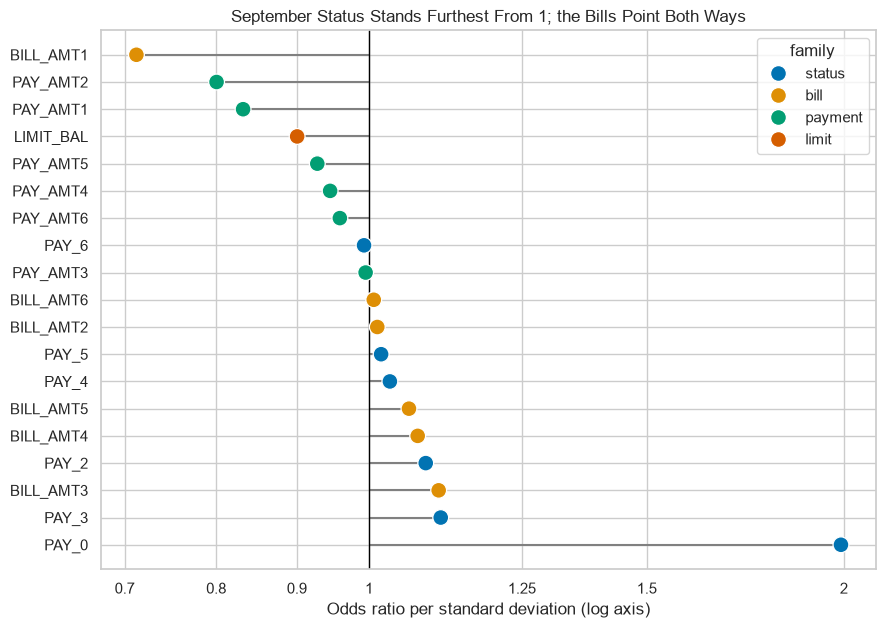

In [47]:
# a lollipop per column: a stick from 1 (no change) to its odds ratio per standard deviation, on a log axis
plt.figure(figsize=(10, 7))
plt.hlines(odds_19.index, 1, odds_19, color="gray")
sns.scatterplot(x=odds_19, y=odds_19.index, hue=family, hue_order=["status", "bill", "payment", "limit"], s=130, zorder=3)
plt.axvline(1, color="black", linewidth=1)
plt.xscale("log")
plt.xticks([0.7, 0.8, 0.9, 1, 1.25, 1.5, 2], ["0.7", "0.8", "0.9", "1", "1.25", "1.5", "2"])
plt.minorticks_off()
plt.legend(title="family")
plt.xlabel("Odds ratio per standard deviation (log axis)")
plt.ylabel("")
plt.title("September Status Stands Furthest From 1; the Bills Point Both Ways")
plt.show()

`PAY_0` sits furthest from 1, at 1.99 per standard deviation; 10 ratios sit above 1 and 9 below.

`BILL_AMT1` (0.71) and `BILL_AMT3` (1.11) point opposite ways, though the two bills move together (correlation 0.90).

That is Day 3's multicollinearity, so the sticks are not a ranking of what matters.

**Nineteen odds ratios; next, their probabilities on accounts the model never saw.**

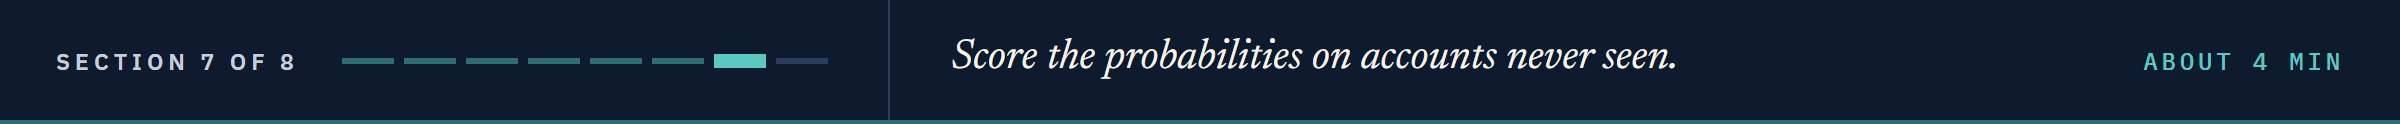

# Model Performance Evaluation

## Probabilities on Validation Accounts

`predict_proba` returns the probability of 0 and of 1 for each account; `[:, 1]` takes every row of the second column.

**Predict 4**

22.12 percent of the 6,000 validation accounts defaulted.

Write down the mean of the model's 6,000 probabilities.

In [48]:
# the model probability of default for every validation account
proba_valid = model.predict_proba(X_valid)[:, 1]
print("Mean model probability:", round(proba_valid.mean(), 4))

Mean model probability: 0.2187


0.2187, near the 0.2212 rate: a logistic regression's probabilities add up to the number of defaults on its training accounts.

### Probabilities by Outcome

Q. Do the accounts that defaulted get higher probabilities than the accounts that paid?

In [49]:
# count the probabilities in bins 0.02 wide, apart for each outcome (np.histogram counts without drawing; _ keeps the edges we already have)
bins = np.arange(0, 1.02, 0.02)
defaulted, _ = np.histogram(proba_valid[y_valid == 1], bins)
paid, _ = np.histogram(proba_valid[y_valid == 0], bins)
print("Mean model probability, paid:", round(proba_valid[y_valid == 0].mean(), 4), " defaulted:", round(proba_valid[y_valid == 1].mean(), 4))

Mean model probability, paid: 0.187  defaulted: 0.3304


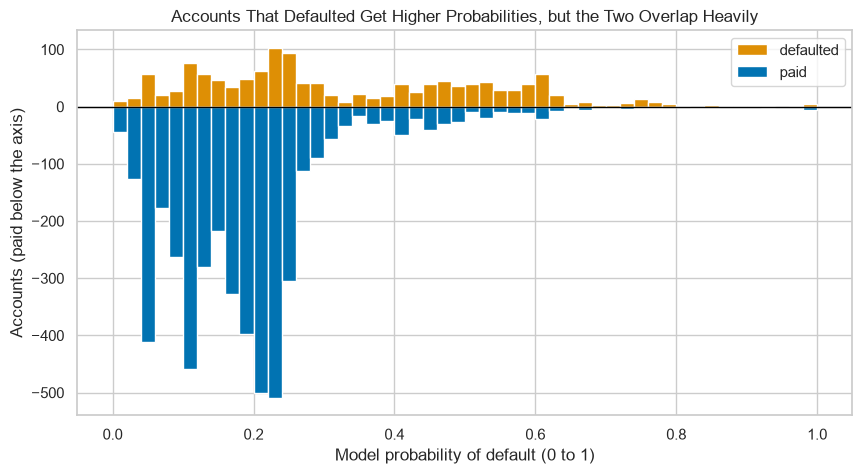

In [50]:
# defaulted above the axis, paid below it: a mirrored histogram
plt.bar(bins[:-1], defaulted, width=0.02, align="edge", color="C1", label="defaulted")
plt.bar(bins[:-1], -paid, width=0.02, align="edge", color="C0", label="paid")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Model probability of default (0 to 1)")
plt.ylabel("Accounts (paid below the axis)")
plt.title("Accounts That Defaulted Get Higher Probabilities, but the Two Overlap Heavily")
plt.legend()
plt.show()

Accounts that defaulted average 0.3304, accounts that paid 0.1870, and the two shapes overlap heavily.

Most defaulted accounts got a probability below 0.5: a probability is not yet a yes or a no, and Day 7 draws that line.

## One Feature, Two, Nineteen

Q. How much does each model add over a flat guess, on training and on validation accounts?

In [51]:
# log loss of the four models on training and on validation accounts (lower is better)
flat_train = np.full(len(y_train), y_train.mean())
p2_train = logit_two.predict(sm.add_constant(X2_train))
p2_valid = logit_two.predict(sm.add_constant(X2_valid))
rows = {"flat guess": [log_loss(y_train, flat_train), log_loss(y_valid, flat_valid)],
        "PAY_0": [log_loss(y_train, p_train), log_loss(y_valid, p_valid)],
        "PAY_0 and limit": [log_loss(y_train, p2_train), log_loss(y_valid, p2_valid)],
        "all 19 columns": [log_loss(y_train, model.predict_proba(X_train)[:, 1]), log_loss(y_valid, proba_valid)]}
scores = pd.DataFrame(rows, index=["training", "validation"]).T
scores

,training,validation
flat guess,0.5285,0.5284
PAY_0,0.4720,0.4820
PAY_0 and limit,0.4678,0.4784
all 19 columns,0.4624,0.4737


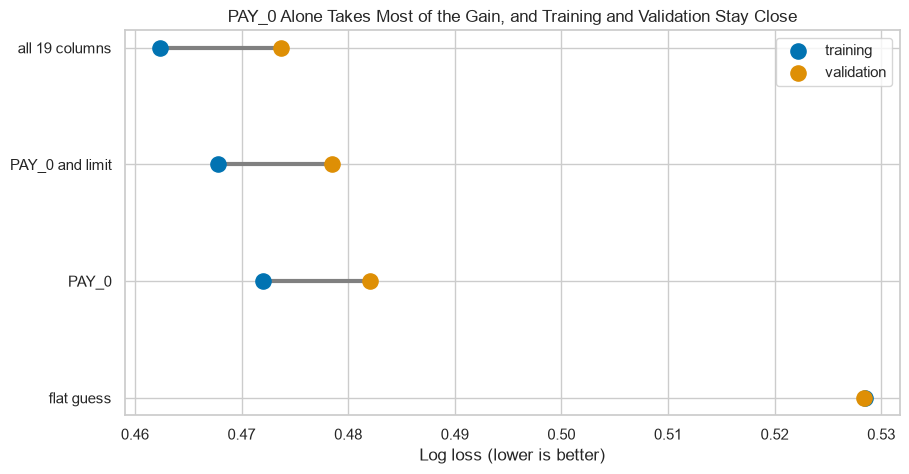

In [52]:
# one row per model, training and validation joined by a line (a dumbbell, as Day 2 drew)
plt.hlines(scores.index, scores["training"], scores["validation"], color="gray", linewidth=3)
plt.scatter(scores["training"], scores.index, s=120, label="training", zorder=3)
plt.scatter(scores["validation"], scores.index, s=120, label="validation", zorder=3)
plt.xlabel("Log loss (lower is better)")
plt.title("PAY_0 Alone Takes Most of the Gain, and Training and Validation Stay Close")
plt.legend()
plt.show()

On validation accounts: flat 0.5284, `PAY_0` 0.4820, with the limit 0.4784, all 19 columns 0.4737.

`PAY_0` alone takes most of the gain, and the training to validation gap stays about 0.01: nineteen features have not memorised the training accounts.

**The 19-column pipeline is the week's model; Day 7 turns its probabilities into flags and counts what they catch.**

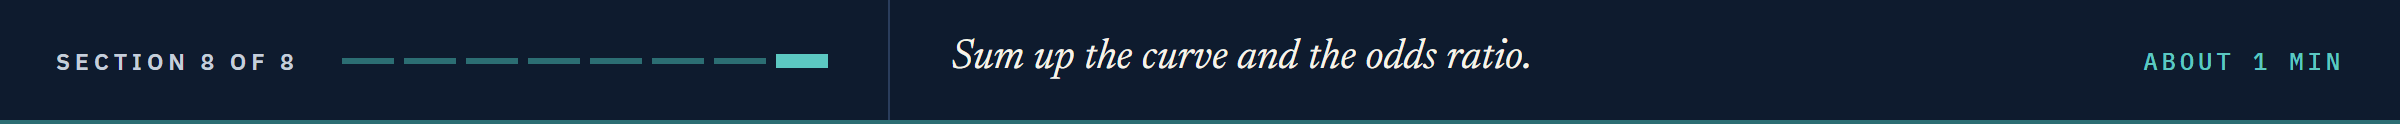

# Insights and Conclusion

A straight line leaves 0 to 1; a logistic regression cannot, because its line lives in log odds and the S curve bends it back.

e to the power of a slope is an odds ratio, and its size depends on the feature's unit.

September status alone gives most of the 19-column model's gain over a flat guess.

Codes -2 to 0 do not support treating the codes as evenly spaced numbers.

Every number describes these accounts, in Taiwan in 2005, and no model probability is a decision about a person.

**A probability needs a curve, and an odds ratio needs its unit.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Say why a straight line fails on a 0/1 outcome.
* Move a number between probability, odds and log odds.
* Fit a logistic regression with statsmodels and scikit-learn.
* Read a coefficient as an odds ratio, with its unit.
* Score probabilities with log loss on validation accounts.

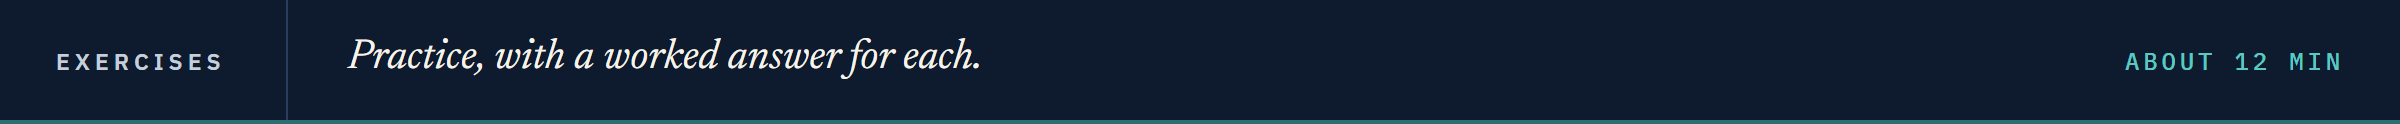

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [53]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Repayment Status in August**

Q. Fit a logistic regression of default on `PAY_2` alone with statsmodels, on the training accounts. Store its coefficient in `ex1_coef` and its odds ratio per code step in `ex1_odds_ratio`.

In [54]:
# your code here
ex1_coef = ...
ex1_odds_ratio = ...

In [55]:
check("Exercise 1 the coefficient", ex1_coef, 0.519932297306084)
check("Exercise 1 the odds ratio", ex1_odds_ratio, 1.6819137757505906)

Exercise 1 the coefficient: not attempted yet
Exercise 1 the odds ratio: not attempted yet


### Exercise 2

**The Limit per 50,000**

Q. From the two-feature model, `logit_two`, compute the limit's odds ratio per 50,000 NT dollars and store it in `ex2_odds_ratio`.

In [56]:
# your code here
ex2_odds_ratio = ...

In [57]:
check("Exercise 2 the odds ratio per 50,000", ex2_odds_ratio, 0.9033575637518404)

Exercise 2 the odds ratio per 50,000: not attempted yet


### Exercise 3

**Odds From a Probability**

Q. Write a function `odds(p)` that returns the odds of a probability `p`, and test it with three `assert` lines: 0.5 gives 1, 0.75 gives 3, and 0.2 gives 0.25. Then store the odds of default on the training accounts in `ex3_odds`.

In [58]:
# your code here
ex3_odds = ...

In [59]:
check("Exercise 3 the training odds of default", ex3_odds, 0.2840633471251248)

Exercise 3 the training odds of default: not attempted yet


### Exercise 4: AI check

**The Odds Ratios Left in Log Units**

You asked an AI assistant for a function that returns each feature's odds ratio from a statsmodels logistic regression.

It runs, and the table looks plausible.

Test it, then find the one bug.

In [60]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def odds_ratio_table(result):
    # the odds ratio of each feature, without the intercept
    return result.params.drop("const")

print(odds_ratio_table(logit_two))

PAY_0        0.7213
LIMIT_10K   -0.0203
dtype: float64


In [61]:
# two checks every odds ratio passes: it is above 0, and it equals e to the power of its coefficient (np.allclose: equal to rounding)
table = odds_ratio_table(logit_two)
assert (table > 0).all(), "an odds ratio is never 0 or below"
assert np.allclose(table, np.exp(logit_two.params.drop("const"))), "an odds ratio is e to the power of its coefficient"

AssertionError: an odds ratio is never 0 or below

Q. Which check fails, and why? Fix the one wrong line and store the fixed table's `PAY_0` value in `ex4_pay_ratio`.

In [62]:
# your code here
ex4_pay_ratio = ...

In [63]:
check("Exercise 4 the fixed PAY_0 odds ratio", ex4_pay_ratio, 2.0570903919202737)

Exercise 4 the fixed PAY_0 odds ratio: not attempted yet


## Congratulations!

You fitted your first model of a 0/1 outcome today, start to finish.
You watched a straight line break the rules of probability, fitted a curve by hand, and let maximum likelihood find the top of the hill.
You read slopes as odds ratios, followed one account to 0.3371, and scored nineteen columns on accounts the model never saw.
In Day 7 the probabilities become flags, and you count what a flag catches and what it misses.

[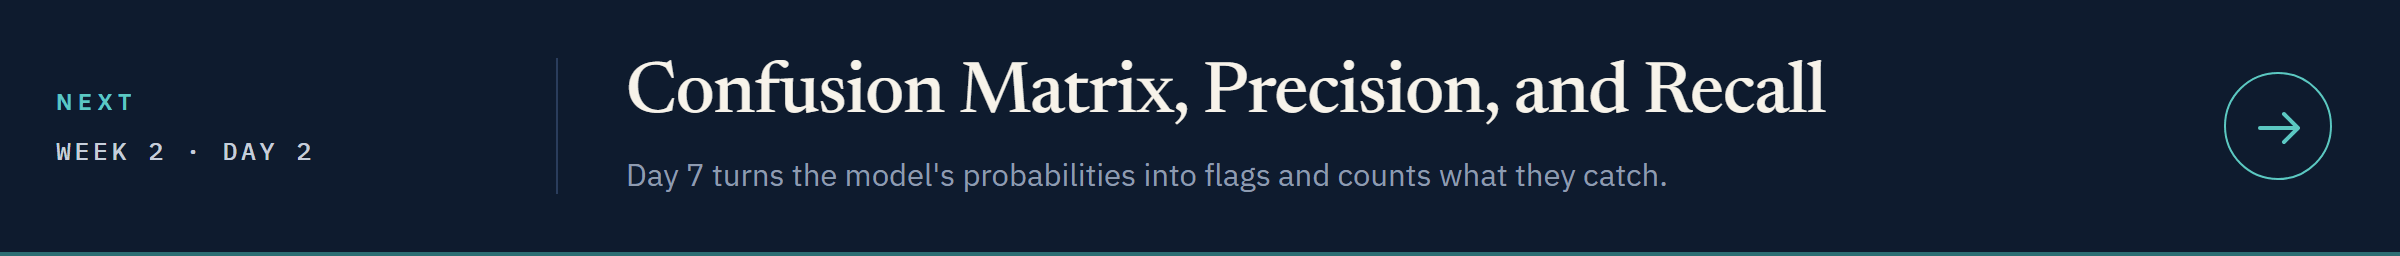](../day2/07_confusion_matrix_precision_and_recall.ipynb)

[Open Day 2 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week2/day2/07_confusion_matrix_precision_and_recall.ipynb)